# HEIMDALL — GLOBAL SOLUTION 2026.2
## Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos

**Tema:** CitizenTech — Inteligência Artificial para uma sociedade melhor  
**Projeto:** Heimdall — identificação de possíveis doenças em folhas de tomate

### Integrantes
- **Adalberto Alves Cruz — RM574115**
- **Danilo Keithi Makiya Nakasone — RM574137**
- **Gustavo da Silva Nascimento — RM570821**

### Objetivo do trabalho
Criar e comparar redes neurais capazes de **classificar imagens de folhas de tomate** em três classes: saudável, pinta-preta e requeima. O modelo será uma **triagem inicial**, e não um diagnóstico agronômico definitivo.

## 1. Problema, público e aplicação

**Problema:** Uma doença não percebida na lavoura pode reduzir a produção de alimentos e prejudicar a renda do agricultor. O Heimdall ajuda **do pequeno produtor às cooperativas e redes que compram dessas fazendas** com alertas e análise de informações.

**O que esta rede neural faz?** Recebe a **foto de uma folha** (imagem colorida) e retorna uma das três classes:

| Classe | O que significa | Possível orientação |
|---|---|---|
| **Saudável** | Sem sinais daquelas duas doenças na imagem analisada | Manter observação |
| **Pinta-preta** | Padrões visuais compatíveis com *Early blight* | Solicitar avaliação técnica |
| **Requeima** | Padrões visuais compatíveis com *Late blight* | Solicitar avaliação técnica |

**Entrada:** imagem RGB (três canais: vermelho, verde e azul).  
**Saída:** nome da classe, nível de confiança e mensagem ao produtor.

**Integração com as outras matérias:** o ESP32 (AICSS) mede as condições do solo, o ML prevê umidade em 24 horas e a rede neural faz uma triagem de folhas por imagens.


### 1.1 O Heimdall e esta disciplina

O **Heimdall** é uma plataforma de IoT e IA contra a perda de alimentos **do campo à mesa**. A mesma solução atende o pequeno (agricultor familiar, feirante, sacolão), o médio (cooperativas e redes regionais de hortifruti) e o grande (redes de supermercado, distribuidores e programas públicos), no campo e na cidade. A cadeia tem quatro elos: irrigação no campo, saúde da lavoura, armazenamento e transporte, e varejo.

| Item | Nesta disciplina |
|---|---|
| **Elo da cadeia** | Campo, saúde da lavoura: perceber uma doença na folha antes que ela se espalhe e destrua a produção |
| **De onde vêm os dados** | Fotos de folhas de tomate (PlantVillage). O tomate é a mesma cultura usada no ESP32 (AICSS) e na API Python do grupo |
| **Para onde vai o resultado** | A classe e a confiança viram um alerta para o produtor, ao lado dos alertas de solo seco (ESP32, API e ML). Uma lavoura saudável e bem irrigada entrega mais alimento para cooperativas, feiras e supermercados, onde a API segue acompanhando a temperatura e o risco de perda dos lotes |
| **Implementado e evolução** | Implementado: três arquiteturas comparadas, busca de hiperparâmetros, avaliação e demonstração com imagens de teste. Evolução: receber a foto pelo celular do produtor e registrar o resultado na mesma API do Heimdall |


## 2. Bibliotecas e configurações

Bibliotecas:

- **TensorFlow / Keras:** constroem e treinam a rede neural.
- **NumPy:** guarda os valores numéricos das imagens.
- **Pandas:** organiza a tabela com a comparação dos modelos.
- **Matplotlib:** mostra imagens e gráficos de treinamento.
- **scikit-learn:** divide os dados e calcula métricas de classificação.
- **TensorFlow Datasets:** baixa o PlantVillage.

Vamos utilizar **300 imagens de cada classe** (900 no total). Não representa o dataset inteiro.

Instalação de bibliotecas para o projeto.

In [ ]:
%pip install -q importlib_resources

In [ ]:
%pip install -q tensorflow

In [ ]:
# IMPORTAÇÃO DAS BIBLIOTECAS
import importlib.util
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

SEMENTE = 42               # Ajuda a reproduzir a mesma divisão dos dados.
TAMANHO = 128              # Cada imagem será redimensionada para 128 x 128.
IMAGENS_POR_CLASSE = 300   # Quantas imagens usaremos para cada classe.
BATCH_SIZE = 32            # Quantas imagens a rede analisa por atualização.
NOMES_CLASSES = ['Saudável', 'Pinta-preta', 'Requeima']

np.random.seed(SEMENTE)
keras.utils.set_random_seed(SEMENTE)

print('Versão do TensorFlow:', tf.__version__)
print('GPU disponível:', tf.config.list_physical_devices('GPU'))

Versão do TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Dataset PlantVillage

**Fonte oficial:** [TensorFlow Datasets — PlantVillage](https://www.tensorflow.org/datasets/catalog/plant_village). O conjunto apresenta imagens de folhas saudáveis e de folhas com doenças.

Vamos selecionar somente três categorias de tomate:

- `Tomato___healthy` → classe **0** (Saudável)
- `Tomato___Early_blight` → classe **1** (Pinta-preta)
- `Tomato___Late_blight` → classe **2** (Requeima)

**Por que essa base?** Porque o problema do Heimdall envolve agricultura, e uma CNN aprende padrões visuais como manchas, cores e texturas. As imagens foram produzidas em condições relativamente padronizadas; fotos tiradas no campo podem ser muito diferentes.

In [ ]:
# CARREGAR O DATASET E SELECIONAR AS 3 CLASSES DE TOMATE

# O PlantVillage do TFDS possui um split chamado 'train'.
# Nós criaremos nossos próprios conjuntos de treino, validação e teste.
dados, info = tfds.load(
    'plant_village',
    split='train',
    as_supervised=True,       # Cada exemplo virá como (imagem, rótulo).
    with_info=True,
    shuffle_files=True,
    read_config=tfds.ReadConfig(shuffle_seed=SEMENTE)
)

# Descobre os nomes dos rótulos usados pelo dataset.
nomes_originais = info.features['label'].names

# Relaciona o nome original ao número da nossa classe.
classes_escolhidas = {
    'tomato___healthy': 0,
    'tomato___early_blight': 1,
    'tomato___late_blight': 2
}

# Verifica se os nomes realmente existem no dataset.
nomes_disponiveis = [nome.lower() for nome in nomes_originais]
for nome in classes_escolhidas:
    assert nome in nomes_disponiveis, f'Classe não encontrada: {nome}'

# Embaralha para não pegar apenas imagens próximas na ordem original.
dados = dados.shuffle(1000, seed=SEMENTE, reshuffle_each_iteration=False)

X = []       # Lista que guardará as imagens.
y = []       # Lista que guardará o número de cada classe.
contagem = [0, 0, 0]

for imagem, rotulo in tfds.as_numpy(dados):
    nome = nomes_originais[int(rotulo)].lower()

    if nome in classes_escolhidas:
        classe = classes_escolhidas[nome]

        # Limitamos a 300 imagens de cada classe para simplificar.
        if contagem[classe] < IMAGENS_POR_CLASSE:
            foto = Image.fromarray(imagem).convert('RGB').resize((TAMANHO, TAMANHO))
            X.append(np.array(foto, dtype=np.uint8))
            y.append(classe)
            contagem[classe] += 1

    if all(numero == IMAGENS_POR_CLASSE for numero in contagem):
        break

# Converte as listas em arrays NumPy, usados pelo Keras.
X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int32)

assert all(numero == IMAGENS_POR_CLASSE for numero in contagem), 'Não foi possível obter 300 imagens por classe.'
print('Imagens carregadas:', len(X))
print('Formato:', X.shape, '-> (quantidade, altura, largura, canais RGB)')
print('Quantidade por classe:', dict(zip(NOMES_CLASSES, contagem)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Imagens carregadas: 900
Formato: (900, 128, 128, 3) -> (quantidade, altura, largura, canais RGB)
Quantidade por classe: {'Saudável': 300, 'Pinta-preta': 300, 'Requeima': 300}


### 3.1 Conhecendo as imagens antes de treinar
Vamos visualizar uma foto de cada classe e a quantidade de imagens escolhidas.

**O que observamos:** diferenças de cor, manchas e lesões; nem sempre duas doenças são fáceis de distinguir apenas pela aparência. Uma distribuição equilibrada ajuda a não favorecer uma classe simplesmente por ela ter mais exemplos.

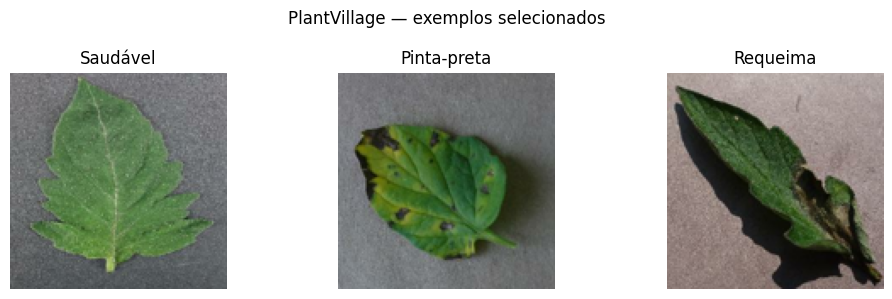

Distribuição das classes:
Requeima       300
Saudável       300
Pinta-preta    300


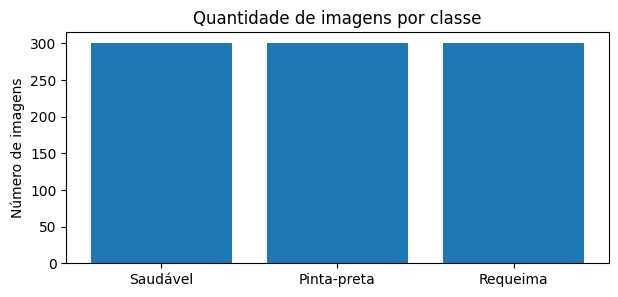

In [ ]:
# VISUALIZAR UMA FOLHA DE CADA CLASSE
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for classe in range(3):
    posicao = np.where(y == classe)[0][0]  # Primeira imagem dessa classe.
    axes[classe].imshow(X[posicao])
    axes[classe].set_title(NOMES_CLASSES[classe])
    axes[classe].axis('off')

plt.suptitle('PlantVillage — exemplos selecionados')
plt.tight_layout()
plt.show()

# Quantas fotos cada classe possui?
contagem_classes = pd.Series(y).map(dict(enumerate(NOMES_CLASSES))).value_counts()
print('Distribuição das classes:')
print(contagem_classes.to_string())

plt.figure(figsize=(7, 3))
plt.bar(NOMES_CLASSES, np.bincount(y, minlength=3))
plt.title('Quantidade de imagens por classe')
plt.ylabel('Número de imagens')
plt.show()

### 3.2 Quantidade de imagens

Nas imagens apresentadas, podemos observar diferenças visuais entre folhas saudáveis e folhas com sinais de pinta-preta e requeima, como mudanças na coloração e presença de lesões. Essas características são o tipo de padrão que uma CNN tenta aprender.

O gráfico de barras confirma uma **amostra equilibrada**: **300 imagens saudáveis, 300 com pinta-preta e 300 com requeima**, totalizando **900 imagens**. O equilíbrio ajuda a comparar as classes sem favorecer uma delas apenas por ter mais exemplos.


## 4. Preparação: treino, validação e teste

Antes de ensinar a rede, dividimos a base em três grupos **sem sobreposição**:

| Grupo | Proporção | Para que serve? |
|---|---|---|
| **Treino** | 70% | A rede ajusta seus pesos usando essas imagens. |
| **Validação** | 15% | Escolhemos a melhor configuração e verificamos se ela está generalizando. |
| **Teste** | 15% | Avaliação final em fotos que não foram usadas para treinar nem selecionar o modelo. |

A divisão é **estratificada** (`stratify=y`) para preservar a proporção das classes. O aumento artificial de imagens (*data augmentation*) será aplicado **somente durante o treinamento**, dentro das redes que o utilizam, evitando misturar cópias entre os conjuntos.

**Por que não normalizamos aqui?** Nas duas CNNs feitas do zero, a normalização será feita pela camada `Rescaling(1./255)`. Na MobileNetV2, a transformação correta é diferente: valores de −1 até 1. Fazemos cada transformação **dentro do respectivo modelo** para evitar erros na hora da previsão.

In [ ]:
# DIVISÃO ESTRATIFICADA: 70% TREINO, 15% VALIDAÇÃO, 15% TESTE

# Passo 1: reserva 15% para o teste final.
X_parcial, X_teste, y_parcial, y_teste = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEMENTE
)

# Passo 2: dos 85% restantes, separa o equivalente a 15% do total.
X_treino, X_val, y_treino, y_val = train_test_split(
    X_parcial, y_parcial,
    test_size=0.15/0.85, stratify=y_parcial, random_state=SEMENTE
)

print('Treino:', len(X_treino), 'imagens')
print('Validação:', len(X_val), 'imagens')
print('Teste:', len(X_teste), 'imagens')
print('Distribuição do treino:', np.bincount(y_treino, minlength=3))
print('Distribuição da validação:', np.bincount(y_val, minlength=3))
print('Distribuição do teste:', np.bincount(y_teste, minlength=3))

Treino: 630 imagens
Validação: 135 imagens
Teste: 135 imagens
Distribuição do treino: [210 210 210]
Distribuição da validação: [45 45 45]
Distribuição do teste: [45 45 45]


### 4.1 Interpretação da divisão dos dados

Foram reservadas **630 imagens para treinamento (70%)**, **135 para validação (15%)** e **135 para teste (15%)**. A divisão foi estratificada: o treinamento ficou com **210 imagens de cada classe**, e a validação e o teste ficaram com **45 imagens por classe** em cada conjunto.

O **treino** ensina a rede; a **validação** ajuda a escolher a configuração; o **teste** permite verificar o desempenho final com imagens que não participaram do ajuste dos pesos. Essa separação é importante para não escolher o modelo com base nos resultados do teste.


## 5. Entendendo a arquitetura CNN

Vamos construir a rede usando `keras.Sequential`

- **`Conv2D` (convolução):** aprende pequenos padrões da imagem, como bordas e manchas.
- **`MaxPooling2D`:** reduz o tamanho das informações e mantém os padrões mais fortes.
- **`Flatten`:** transforma os mapas de características em uma sequência de números.
- **`Dense`:** combina o que foi aprendido para escolher uma classe.
- **`Dropout`:** desliga temporariamente parte dos neurônios no treino para reduzir overfitting.
- **`softmax`:** gera três pontuações que somam 100%, uma para cada classe.

Uma **época** é uma passagem pelos dados de treino. O **batch size** é a quantidade de imagens processada de cada vez. O **learning rate** controla o tamanho dos ajustes dos pesos.

| Configuração | Principal diferença | Épocas máximas | Learning rate |
|---|---|---:|---:|
| 1. CNN simples | Duas convoluções, sem regularização forte | 8 | 0,001 |
| 2. CNN melhorada | Aumento de dados, BatchNormalization, Dropout e EarlyStopping | 12 | 0,0005 |
| 3. MobileNetV2 | Transfer learning com uma base pré-treinada congelada | 8 | 0,0001 |
| 4. MobileNetV2 otimizada | Busca de learning rate, neurônios da camada densa e batch size (seção 7.1) | 8 | 0,001 a 0,0001 |

### 5.1 Modelo 1 — CNN simples (nossa referência)

Nesta primeira versão, treinamos as convoluções **do zero**. A rede aprende a reconhecer padrões diretamente das fotos de tomate.

**Loss:** `sparse_categorical_crossentropy`, apropriada quando as classes são números inteiros (`0`, `1` e `2`).  
**Métrica:** `accuracy`, porcentagem de imagens classificadas corretamente.

In [ ]:
# MODELO 1 — CNN SIMPLES

modelo_simples = keras.Sequential([
    layers.Input(shape=(TAMANHO, TAMANHO, 3)),
    layers.Rescaling(1./255),                  # Pixels de 0–255 para 0–1.

    layers.Conv2D(16, 3, activation='relu'),   # Aprende 16 padrões visuais.
    layers.MaxPooling2D(),                    # Reduz o tamanho dos mapas.
    layers.Conv2D(32, 3, activation='relu'),   # Aprende 32 padrões mais complexos.
    layers.MaxPooling2D(),

    layers.Flatten(),                          # Transforma os mapas em uma lista.
    layers.Dense(32, activation='relu'),       # Combina as características.
    layers.Dense(3, activation='softmax')      # Três classes: 0, 1 e 2.
], name='cnn_simples')

modelo_simples.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Mostra camadas, formatos e número de parâmetros treináveis.
modelo_simples.summary()

Model: "cnn_simples"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       921,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 926,819 (3.54 MB)

 Trainable params: 926,819 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

A coluna **Output Shape** mostra como o tamanho dos dados muda entre as camadas. A coluna **Param #** indica quantos pesos a rede precisa aprender. Em geral, redes com mais parâmetros podem aprender padrões mais complexos, mas também podem decorar as imagens de treinamento.

A seguir, usamos `.fit()` para treinar. O Keras mostrará, a cada época, `accuracy` e `loss` de **treino** e `val_accuracy` / `val_loss` de **validação**.

In [ ]:
# TREINAMENTO DA CNN SIMPLES

inicio = time.time()  # Marca o começo para medir o tempo de treinamento.

historico_simples = modelo_simples.fit(
    X_treino, y_treino,
    validation_data=(X_val, y_val),
    epochs=8,                         # No máximo 8 passagens pelos dados.
    batch_size=BATCH_SIZE,
    verbose=1
)

tempo_simples = time.time() - inicio
print(f'Tempo da CNN simples: {tempo_simples:.1f} segundos')

Epoch 1/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 30s 966ms/step - accuracy: 0.3683 - loss: 1.1059 - val_accuracy: 0.5852 - val_loss: 1.0481
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6492 - loss: 0.8817 - val_accuracy: 0.7481 - val_loss: 0.6989
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7492 - loss: 0.6113 - val_accuracy: 0.6889 - val_loss: 0.6240
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8238 - loss: 0.4557 - val_accuracy: 0.8519 - val_loss: 0.4784
Epoch 5/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8984 - loss: 0.3080 - val_accuracy: 0.8370 - val_loss: 0.4193
Epoch 6/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9286 - loss: 0.2038 - val_accuracy: 0.8296 - val_loss: 0.4144
Epoch 7/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9556 - loss: 0.1286 - val_accuracy: 0.8370 - val_loss: 0.3993
Epoch 8/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9841 - loss: 0.0847 - val_accuracy: 0.8296 - val_los

## 6. Modelo 2 — CNN melhorada

Agora faremos uma **segunda configuração** para investigar se é possível melhorar a generalização:

- **`RandomFlip` / `RandomRotation` / `RandomZoom`:** pequenas mudanças nas imagens **durante o treino**, para que a rede não dependa sempre da mesma posição.
- **`BatchNormalization`:** ajuda a estabilizar o treinamento.
- **`Dropout(0.4)`:** desliga aproximadamente 40% das saídas daquela camada durante o treino; não atua na previsão.
- **`EarlyStopping`:** interrompe o treino quando `val_loss` deixa de melhorar e recupera os melhores pesos.
- **`ReduceLROnPlateau`:** diminui o learning rate quando a perda de validação para de cair.

Vamos comparar **acurácia de validação**, **F1-score de teste** e as curvas de treino/validação.

In [ ]:
# MODELO 2 — CNN COM REGULARIZAÇÃO

# Data augmentation = pequenas mudanças aleatórias APENAS no treinamento.
aumento = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
], name='aumento_de_dados')

modelo_melhorado = keras.Sequential([
    layers.Input(shape=(TAMANHO, TAMANHO, 3)),
    aumento,
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(3, activation='softmax')
], name='cnn_melhorada')

modelo_melhorado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo_melhorado.summary()

Model: "cnn_melhorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_dados (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,851 (3.15 MB)

 Trainable params: 826,755 (3.15 MB)

 Non-trainable params: 96 (384.00 B)

In [ ]:
# CALLBACKS E TREINAMENTO DA CNN MELHORADA

# EarlyStopping olha a validação, nunca o conjunto de teste.
parada = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

# Se a validação não melhorar, reduz o tamanho dos passos do treinamento.
reduzir_taxa = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001
)

inicio = time.time()

historico_melhorado = modelo_melhorado.fit(
    X_treino, y_treino,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=BATCH_SIZE,
    callbacks=[parada, reduzir_taxa],
    verbose=1
)

tempo_melhorado = time.time() - inicio
print(f'Tempo da CNN melhorada: {tempo_melhorado:.1f} segundos')

Epoch 1/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.5143 - loss: 1.1838 - val_accuracy: 0.3556 - val_loss: 1.0940 - learning_rate: 5.0000e-04
Epoch 2/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7079 - loss: 0.6640 - val_accuracy: 0.3333 - val_loss: 1.0850 - learning_rate: 5.0000e-04
Epoch 3/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7492 - loss: 0.5315 - val_accuracy: 0.3333 - val_loss: 1.0827 - learning_rate: 5.0000e-04
Epoch 4/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.8032 - loss: 0.4402 - val_accuracy: 0.3333 - val_loss: 1.0944 - learning_rate: 5.0000e-04
Epoch 5/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.7635 - loss: 0.4715 - val_accuracy: 0.4519 - val_loss: 1.0072 - learning_rate: 5.0000e-04
Epoch 6/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.7841 - loss: 0.4137 - val_accuracy: 0.3407 - val_loss: 1.0287 - learning_rate: 5.0000e-04
Epoch 7/12
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.8603

## 7. Modelo 3 — Transfer Learning com MobileNetV2

1. Carregar uma rede **pré-treinada no ImageNet**.
2. Usar `include_top=False` para descartar a classificação original.
3. Colocar `trainable=False` na base: **congelamos** os pesos já aprendidos.
4. Adicionar uma **cabeça nova** para nossas três classes de tomate.
5. Treinar apenas as camadas novas, com learning rate pequeno.

**Por que MobileNetV2 e não VGG16?** As duas servem para transfer learning, mas a MobileNetV2 é uma opção mais leve.

### Cuidado importante com as imagens
- Nas CNNs anteriores usamos `Rescaling(1./255)`, resultando em valores de **0 a 1**.
- Na MobileNetV2 os pixels devem ficar na faixa **−1 a 1**, usando `Rescaling(1./127.5, offset=-1)`.

A entrada da rede na **demonstração** será processada do mesmo jeito que no treinamento, porque essa transformação está dentro do próprio modelo. **Não devemos usar as duas normalizações juntas.**

In [ ]:
# MODELO 3 — MOBILENETV2 PRÉ-TREINADA

# Carrega os filtros visuais já treinados no ImageNet.
base_mobile = keras.applications.MobileNetV2(
    input_shape=(TAMANHO, TAMANHO, 3),
    include_top=False,       # Remove as classes originais do ImageNet.
    weights='imagenet'       # Faz download dos pesos na primeira execução.
)
base_mobile.trainable = False  # Somente nossa cabeça nova será treinada.

# O modelo agora usa a API Functional
entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3))
x = layers.RandomFlip('horizontal')(entrada)  # Aumento só durante treino.
x = layers.Rescaling(1./127.5, offset=-1)(x) # RGB [0,255] → [-1,1].
x = base_mobile(x, training=False)           # Mantém a base congelada.
x = layers.GlobalAveragePooling2D()(x)      # Resume os mapas de padrões.
x = layers.Dense(64, activation='relu')(x)  # Nossa cabeça classificadora.
x = layers.Dropout(0.3)(x)                  # Ajuda a reduzir overfitting.
saida = layers.Dense(3, activation='softmax')(x)

modelo_mobile = keras.Model(entrada, saida, name='mobile_tomate')

modelo_mobile.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo_mobile.summary()
print('A base MobileNetV2 está congelada?', not base_mobile.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobile_tomate"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

A base MobileNetV2 está congelada? True


In [ ]:
# TREINAMENTO DA CABEÇA DA MOBILENETV2

parada_mobile = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

inicio = time.time()

historico_mobile = modelo_mobile.fit(
    X_treino, y_treino,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=BATCH_SIZE,
    callbacks=[parada_mobile],
    verbose=1
)

tempo_mobile = time.time() - inicio
print(f'Tempo da MobileNetV2: {tempo_mobile:.1f} segundos')

Epoch 1/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.3667 - loss: 1.2888 - val_accuracy: 0.5926 - val_loss: 0.8760
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.5587 - loss: 0.9147 - val_accuracy: 0.8000 - val_loss: 0.6742
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7079 - loss: 0.7085 - val_accuracy: 0.8222 - val_loss: 0.5565
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7873 - loss: 0.5489 - val_accuracy: 0.8296 - val_loss: 0.4833
Epoch 5/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8111 - loss: 0.4969 - val_accuracy: 0.8519 - val_loss: 0.4301
Epoch 6/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8238 - loss: 0.4388 - val_accuracy: 0.8741 - val_loss: 0.3887
Epoch 7/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8619 - loss: 0.3935 - val_accuracy: 0.8593 - val_loss: 0.3599
Epoch 8/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8667 - loss: 0.3747 - val_accuracy: 0.8815 - val_loss:

### 7.1 Busca de hiperparâmetros na MobileNetV2

A MobileNetV2 foi a configuração mais promissora, então ajustamos seus hiperparâmetros de forma organizada, em duas etapas:

1. **Learning rate e neurônios:** testamos 3 learning rates (0,001, 0,0005 e 0,0001) com 2 tamanhos da camada densa (32 e 128 neurônios), num total de 6 combinações.
2. **Batch size:** com a melhor combinação da etapa 1, testamos batch size 16 e 64, além do 32 já usado.

Regras para a comparação ser justa:
- A base MobileNetV2 continua **congelada**; só a cabeça nova é treinada.
- Todas as combinações usam a mesma semente, o mesmo Dropout (0,3), até 8 épocas e EarlyStopping na `val_loss`.
- A escolha usa **apenas a validação** (maior acurácia; em caso de empate, menor perda). O teste continua guardado para a avaliação final.


In [ ]:
# BUSCA DE HIPERPARÂMETROS NA MOBILENETV2

def criar_mobile(learning_rate, neuronios):
    """Monta a mesma arquitetura do modelo 3, mudando só o learning rate e os neurônios."""
    entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3))
    x = layers.RandomFlip('horizontal')(entrada)
    x = layers.Rescaling(1./127.5, offset=-1)(x)
    x = base_mobile(x, training=False)          # mesma base congelada do modelo 3
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(neuronios, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(3, activation='softmax')(x)

    modelo = keras.Model(entrada, saida)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return modelo


def treinar_combinacao(learning_rate, neuronios, batch):
    """Treina uma combinação e devolve o resultado medido na validação."""
    keras.utils.set_random_seed(SEMENTE)   # mesma semente para todas as combinações
    modelo = criar_mobile(learning_rate, neuronios)
    parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    inicio = time.time()
    historico = modelo.fit(
        X_treino, y_treino,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=batch,
        callbacks=[parada],
        verbose=0
    )
    duracao = time.time() - inicio

    perda_val, acc_val = modelo.evaluate(X_val, y_val, verbose=0)
    print(f'lr = {learning_rate:<7} | neurônios = {neuronios:<3} | batch = {batch:<2} | '
          f'acc validação = {acc_val:.2%} | loss validação = {perda_val:.4f} | '
          f'épocas = {len(historico.history["loss"])} | {duracao:.0f} s')

    return {
        'linha': {
            'Learning rate': learning_rate,
            'Neurônios': neuronios,
            'Batch size': batch,
            'Acc validação': acc_val,
            'Loss validação': perda_val,
            'Épocas': len(historico.history['loss']),
            'Tempo (s)': duracao
        },
        'modelo': modelo,
        'historico': historico,
        'tempo': duracao
    }


def melhor_de(lista):
    """Maior acurácia de validação; no empate, a menor perda de validação."""
    return max(lista, key=lambda r: (r['linha']['Acc validação'], -r['linha']['Loss validação']))


# ETAPA 1: learning rate x neurônios (batch 32)
print('ETAPA 1 - learning rate e neurônios')
etapa1 = []
for lr in [0.001, 0.0005, 0.0001]:
    for n in [32, 128]:
        etapa1.append(treinar_combinacao(lr, n, BATCH_SIZE))

melhor1 = melhor_de(etapa1)
lr_escolhido = melhor1['linha']['Learning rate']
n_escolhido = melhor1['linha']['Neurônios']
print(f'\nMelhor da etapa 1: learning rate = {lr_escolhido} e {n_escolhido} neurônios')

# ETAPA 2: batch size com a melhor combinação da etapa 1
print('\nETAPA 2 - batch size')
etapa2 = [melhor1]
for batch in [16, 64]:
    etapa2.append(treinar_combinacao(lr_escolhido, n_escolhido, batch))

melhor_final = melhor_de(etapa2)
modelo_mobile_otimizado = melhor_final['modelo']
historico_mobile_otimizado = melhor_final['historico']
tempo_mobile_otimizado = melhor_final['tempo']
config_otimizada = melhor_final['linha']

print(f"\nCONFIGURAÇÃO ESCOLHIDA PELA VALIDAÇÃO: learning rate = {config_otimizada['Learning rate']}, "
      f"{config_otimizada['Neurônios']} neurônios, batch size = {config_otimizada['Batch size']} "
      f"(acc validação = {config_otimizada['Acc validação']:.2%})")


ETAPA 1 - learning rate e neurônios
lr = 0.001   | neurônios = 32  | batch = 32 | acc validação = 92.59% | loss validação = 0.1979 | épocas = 8 | 22 s
lr = 0.001   | neurônios = 128 | batch = 32 | acc validação = 93.33% | loss validação = 0.1889 | épocas = 8 | 23 s
lr = 0.0005  | neurônios = 32  | batch = 32 | acc validação = 88.89% | loss validação = 0.2608 | épocas = 8 | 29 s
lr = 0.0005  | neurônios = 128 | batch = 32 | acc validação = 92.59% | loss validação = 0.1735 | épocas = 8 | 22 s
lr = 0.0001  | neurônios = 32  | batch = 32 | acc validação = 78.52% | loss validação = 0.5224 | épocas = 8 | 23 s
lr = 0.0001  | neurônios = 128 | batch = 32 | acc validação = 84.44% | loss validação = 0.3709 | épocas = 8 | 22 s

Melhor da etapa 1: learning rate = 0.001 e 128 neurônios

ETAPA 2 - batch size
lr = 0.001   | neurônios = 128 | batch = 16 | acc validação = 92.59% | loss validação = 0.1669 | épocas = 7 | 49 s
lr = 0.001   | neurônios = 128 | batch = 64 | acc validação = 92.59% | loss val

 Learning rate  Neurônios  Batch size  Acc validação  Loss validação  Épocas  Tempo (s)
        0.0010         32          32         0.9259          0.1979       8    21.7882
        0.0010        128          32         0.9333          0.1889       8    23.2609
        0.0005         32          32         0.8889          0.2608       8    29.2925
        0.0005        128          32         0.9259          0.1735       8    21.9360
        0.0001         32          32         0.7852          0.5224       8    22.9013
        0.0001        128          32         0.8444          0.3709       8    22.3713
        0.0010        128          16         0.9259          0.1669       7    49.1373
        0.0010        128          64         0.9259          0.1627       8    47.2065


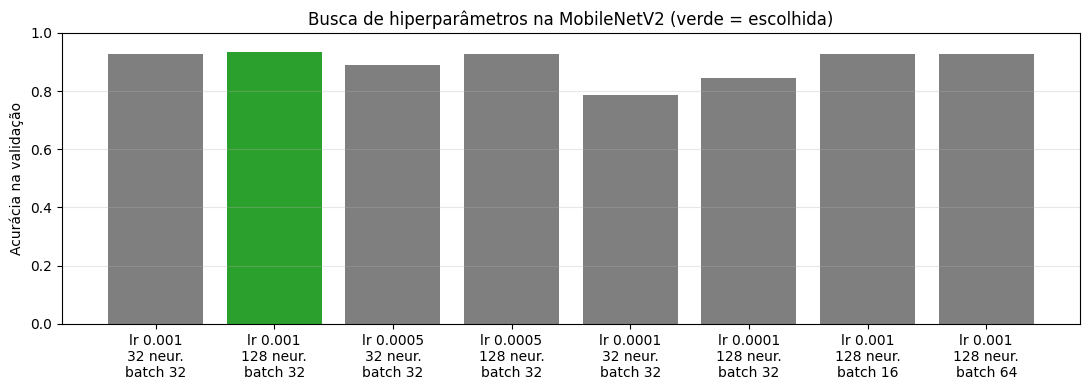

In [ ]:
# TABELA E GRÁFICO DA BUSCA

tabela_busca = pd.DataFrame([r['linha'] for r in etapa1 + etapa2[1:]])
print(tabela_busca.round(4).to_string(index=False))

rotulos = [f"lr {l['Learning rate']}\n{l['Neurônios']} neur.\nbatch {l['Batch size']}" for l in tabela_busca.to_dict('records')]
cores = ['tab:green' if (l['Learning rate'], l['Neurônios'], l['Batch size']) ==
         (config_otimizada['Learning rate'], config_otimizada['Neurônios'], config_otimizada['Batch size'])
         else 'tab:gray' for l in tabela_busca.to_dict('records')]

plt.figure(figsize=(11, 4))
plt.bar(rotulos, tabela_busca['Acc validação'], color=cores)
plt.ylim(0, 1)
plt.ylabel('Acurácia na validação')
plt.title('Busca de hiperparâmetros na MobileNetV2 (verde = escolhida)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### 7.2 Interpretação da busca de hiperparâmetros

Foram testadas **8 combinações** na MobileNetV2, sempre escolhendo pela **acurácia de validação** (o teste não entrou na escolha):

- **Etapa 1 (learning rate x neurônios, batch 32):** a melhor combinação foi **learning rate 0,001 com 128 neurônios**, com **93,33%** de validação. Com **learning rate 0,0001** a rede aprendeu devagar demais para 8 épocas e ficou entre **78,52%** e **84,44%**.
- **Etapa 2 (batch size):** com a melhor combinação da etapa 1, os batches **16** e **64** chegaram a **92,59%**, sem superar o batch **32**.

A configuração escolhida (**learning rate 0,001, 128 neurônios e batch 32**) entra na comparação final como **MobileNetV2 otimizada**, junto com as três configurações anteriores.

## 8. Gráficos de treino e validação

1. **Loss (perda):** mede quanto a previsão está errando segundo a função escolhida. O desejável é que ela diminua.
2. **Accuracy (acurácia):** mede a proporção de classificações corretas. O desejável é que aumente.

**interpretação:**
- Treino e validação com desempenho próximo costumam indicar boa generalização.
- Treino muito melhor que validação pode indicar **overfitting** (a rede memorizou exemplos).
- Treino e validação ruins podem indicar **underfitting** (a rede ainda não aprendeu o suficiente).
- A validação às vezes é melhor que o treino porque `Dropout` e data augmentation atuam no treino, mas não na avaliação.

Os gráficos mostram a **evolução do aprendizado**; não provam, sozinhos, que o sistema funcionará bem.

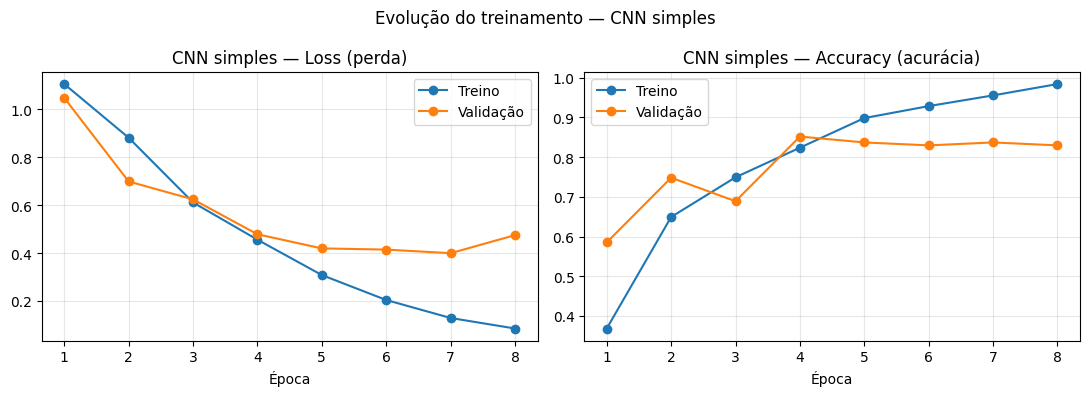

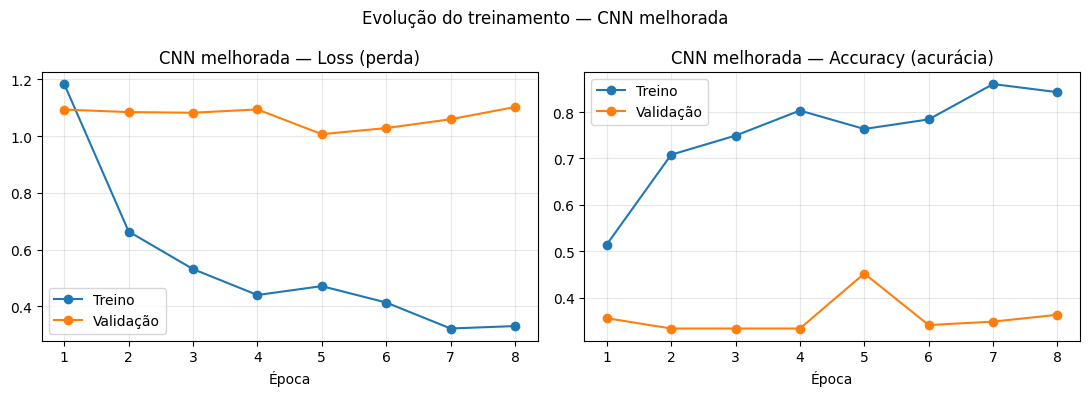

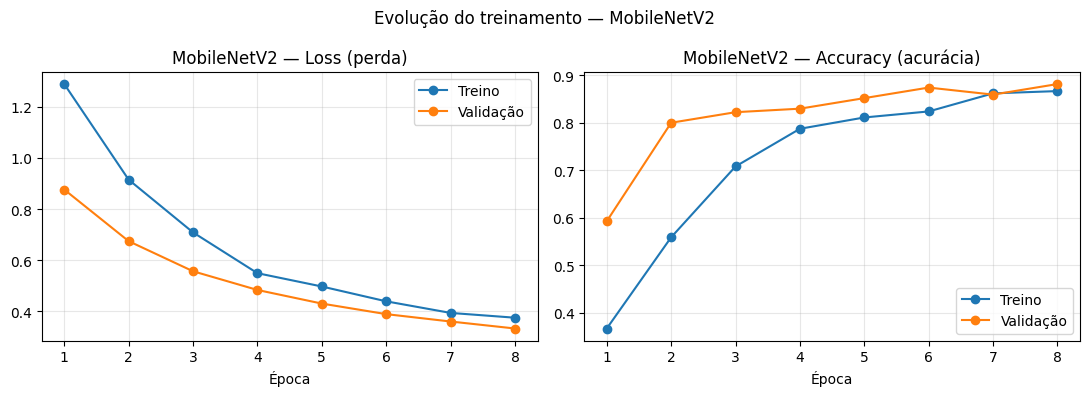

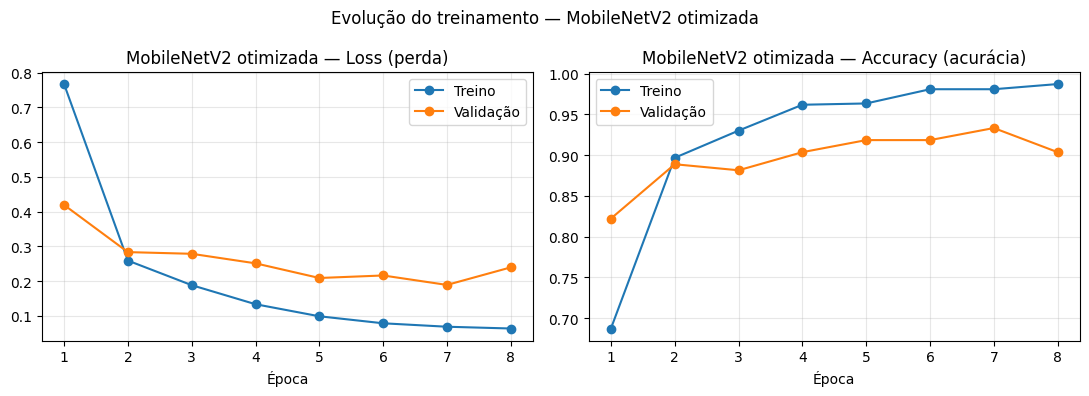

In [ ]:
# GRÁFICOS DE LOSS E ACCURACY — TODAS AS CONFIGURAÇÕES

historicos = {
    'CNN simples': historico_simples,
    'CNN melhorada': historico_melhorado,
    'MobileNetV2': historico_mobile,
    'MobileNetV2 otimizada': historico_mobile_otimizado
}

# Para cada modelo, criamos dois gráficos.
for nome, historico in historicos.items():
    h = historico.history  # Guarda a história das métricas por época.
    epocas = range(1, len(h['loss']) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(epocas, h['loss'], label='Treino', marker='o')
    ax1.plot(epocas, h['val_loss'], label='Validação', marker='o')
    ax1.set_title(nome + ' — Loss (perda)')
    ax1.set_xlabel('Época')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epocas, h['accuracy'], label='Treino', marker='o')
    ax2.plot(epocas, h['val_accuracy'], label='Validação', marker='o')
    ax2.set_title(nome + ' — Accuracy (acurácia)')
    ax2.set_xlabel('Época')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.suptitle('Evolução do treinamento — ' + nome)
    plt.tight_layout()
    plt.show()

### 8.1 Interpretação dos gráficos após a execução

**CNN simples:** a perda (*loss*) do treinamento caiu bastante e a acurácia de treino chegou a **98,6%**, mas a validação terminou em **82,96%**. A diferença de cerca de **15,6 pontos percentuais** e a perda de validação voltando a subir no fim indicam **sinais de overfitting**: a rede decorou bem as imagens de treino e teve mais dificuldade com as que não viu.

**CNN melhorada:** nesta execução o treinamento não se estabilizou. A validação ficou perto de **33%** (o mesmo que chutar uma das três classes) em várias épocas, e o melhor valor foi **45,19%**, com o treino avaliado em **43,2%**. É um caso de **underfitting**: com *data augmentation*, *Dropout* e *BatchNormalization* juntos em poucas épocas, a rede não chegou a aprender os padrões. O resultado também se mostrou instável: numa execução anterior do mesmo código ela chegou a **80,74%** de validação. Isso não quer dizer que as técnicas sejam ruins, e sim que **esta configuração específica** precisa de mais épocas ou outro ajuste.

**MobileNetV2:** as perdas de treino e validação caíram juntas, e a validação chegou a **88,15%**, com treino de **90,6%** (diferença de cerca de **2,5 pontos**). Foi a evolução mais equilibrada entre as configurações sem busca.

**MobileNetV2 otimizada:** com a configuração escolhida na busca, a validação subiu para **93,33%**, com treino de **99,2%** (diferença de **5,87 pontos**). A diferença é maior que a da MobileNetV2 original, mas a validação também é bem mais alta, então o ganho compensa.

**Conclusão dos gráficos:** aumentar a complexidade da rede não garante um resultado melhor. O que mais ajudou foi aproveitar uma rede pré-treinada e ajustar os hiperparâmetros olhando a validação, deixando o teste reservado para a avaliação final.

## 9. Comparação e escolha do modelo

Nossa escolha será feita pela **acurácia de validação**, porque o conjunto de teste deve ficar reservado para a avaliação final.

Depois de escolher o melhor modelo pela validação, vamos medir **as quatro configurações uma única vez no teste**. Não usaremos o desempenho de teste para mudar o vencedor.

**Métricas da comparação:**
- **Acurácia:** quantidade de acertos dividida pelo total de imagens.
- **F1-score macro:** média dos F1 das três classes, dando a mesma importância a cada uma.
- **Épocas:** número de rodadas realmente executadas.
- **Tempo:** esforço computacional observado.

> Uma acurácia alta não significa ausência de erros. Precisamos verificar **quais classes são confundidas** usando a matriz de confusão.

In [ ]:
# SELEÇÃO PELA VALIDAÇÃO (ANTES DE OLHAR O TESTE)

modelos = {
    'CNN simples': modelo_simples,
    'CNN melhorada': modelo_melhorado,
    'MobileNetV2': modelo_mobile,
    'MobileNetV2 otimizada': modelo_mobile_otimizado
}

tempos = {
    'CNN simples': tempo_simples,
    'CNN melhorada': tempo_melhorado,
    'MobileNetV2': tempo_mobile,
    'MobileNetV2 otimizada': tempo_mobile_otimizado
}

# Calcula a acurácia no conjunto de validação.
acuracias_val = {}
for nome, modelo in modelos.items():
    perda, acuracia = modelo.evaluate(X_val, y_val, verbose=0)
    acuracias_val[nome] = acuracia

# Escolhe a rede com a MAIOR acurácia de validação.
vencedor = max(acuracias_val, key=acuracias_val.get)
melhor_modelo = modelos[vencedor]

print('Acurácias na validação:')
for nome, acuracia in acuracias_val.items():
    print(f'{nome}: {acuracia:.2%}')
print('\nMODELO ESCOLHIDO PELA VALIDAÇÃO:', vencedor)

Acurácias na validação:
CNN simples: 82.96%
CNN melhorada: 45.19%
MobileNetV2: 88.15%
MobileNetV2 otimizada: 93.33%

MODELO ESCOLHIDO PELA VALIDAÇÃO: MobileNetV2 otimizada


In [ ]:
# TABELA COMPARATIVA FINAL — TREINO, VALIDAÇÃO E TESTE

linhas = []

for nome, modelo in modelos.items():
    # Mede treino e teste com a rede já treinada.
    _, acc_treino = modelo.evaluate(X_treino, y_treino, verbose=0)
    _, acc_teste = modelo.evaluate(X_teste, y_teste, verbose=0)

    # O modelo devolve três pontuações; argmax escolhe a maior.
    probabilidades = modelo.predict(X_teste, verbose=0)
    classes_previstas = np.argmax(probabilidades, axis=1)

    linhas.append({
        'Modelo': nome,
        'Acc treino': acc_treino,
        'Acc validação': acuracias_val[nome],
        'Acc teste': acc_teste,
        'F1 macro teste': f1_score(y_teste, classes_previstas, average='macro', zero_division=0),
        'Épocas': len(historicos[nome].history['loss']),
        'Tempo (s)': tempos[nome]
    })

# DataFrame deixa a comparação fácil.
tabela = pd.DataFrame(linhas)
print(tabela.round(3).to_string(index=False))

               Modelo  Acc treino  Acc validação  Acc teste  F1 macro teste  Épocas  Tempo (s)
          CNN simples       0.986          0.830      0.844           0.842       8     33.990
        CNN melhorada       0.432          0.452      0.437           0.339       8     19.461
          MobileNetV2       0.906          0.881      0.837           0.836       8     92.782
MobileNetV2 otimizada       0.992          0.933      0.926           0.926       8     23.261


### 9.1 Interpretação da tabela comparativa

A **MobileNetV2 otimizada foi selecionada pela maior acurácia de validação (93,33%)**, comparada com a MobileNetV2 original (**88,15%**), a CNN simples (**82,96%**) e a CNN melhorada (**45,19%**). Esse critério foi definido antes de consultar o teste, para não escolher o modelo pelo resultado final.

No conjunto de **135 imagens reservadas para teste**, foram observados:

| Modelo | Acurácia no teste | F1-score macro | Interpretação |
|---|---:|---:|---|
| CNN simples | **84,44%** | **0,842** | Bom resultado, mas com sinais de overfitting |
| CNN melhorada | **43,70%** | **0,339** | Não aprendeu nesta execução (underfitting) |
| MobileNetV2 | **83,70%** | **0,836** | Curvas equilibradas, mas sem ajuste de hiperparâmetros |
| MobileNetV2 otimizada | **92,59%** | **0,926** | Escolhida pela validação e também a melhor no teste |

O teste confirmou a escolha feita pela validação: a **MobileNetV2 otimizada** acertou **125 de 135 imagens**, cerca de **8 pontos** acima das outras configurações.

A CNN simples teve **98,6%** no treino e **83,0%** na validação, diferença de cerca de **15,6 pontos percentuais**. A MobileNetV2 otimizada teve **99,2%** no treino e **93,3%** na validação, diferença de **5,87 pontos**. Essas diferenças, junto com os gráficos, ajudam a discutir overfitting e generalização.

**Importante:** resultados em imagens do PlantVillage não garantem a mesma qualidade em fotos tiradas diretamente em lavouras.

### 9.2 Como interpretar treino e validação

Comparamos **Acc treino** e **Acc validação**. Quando o resultado no treino é muito alto, mas a validação fica bem atrás, pode haver **overfitting** (o modelo se ajustou demais às imagens de treinamento). Se os dois resultados forem baixos, pode haver **underfitting** (o modelo ainda não aprendeu padrões suficientes).

A diferença entre essas métricas é um indício, não uma prova isolada. Também observamos a evolução de *Loss* e *Accuracy* nos gráficos.

In [ ]:
# RESUMO AUTOMÁTICO COM OS RESULTADOS REAIS

linha_vencedor = tabela.loc[tabela['Modelo'] == vencedor].iloc[0]
diferenca = linha_vencedor['Acc treino'] - linha_vencedor['Acc validação']

print('Modelo selecionado:', vencedor)
print(f'Acurácia de validação: {linha_vencedor["Acc validação"]:.2%}')
print(f'Acurácia de teste: {linha_vencedor["Acc teste"]:.2%}')
print(f'F1-score macro de teste: {linha_vencedor["F1 macro teste"]:.3f}')
print(f'Diferença treino - validação: {diferenca:.2%} (pontos percentuais)')
print('Interprete a diferença junto com os gráficos; ela não prova overfitting sozinha.')

Modelo selecionado: MobileNetV2 otimizada
Acurácia de validação: 93.33%
Acurácia de teste: 92.59%
F1-score macro de teste: 0.926
Diferença treino - validação: 5.87% (pontos percentuais)
Interprete a diferença junto com os gráficos; ela não prova overfitting sozinha.


## 10. Matriz de confusão, Precision, Recall e F1 (etapa 7 da GS)

A **matriz de confusão** permite identificar **que tipo de erro** a rede comete:

- **Linhas:** classe verdadeira da imagem.
- **Colunas:** classe que a rede previu.
- **Diagonal:** quantidade de acertos.
- **Fora da diagonal:** classificações incorretas.

**Precision (precisão):** entre as folhas que a rede apontou como uma classe, quantas pertenciam realmente a ela?  
**Recall (revocação):** entre todas as folhas que realmente pertenciam à classe, quantas a rede conseguiu reconhecer?  
**F1-score:** combina precision e recall em um único indicador.

**Cuidado no Heimdall:** quando uma folha **doente é prevista como saudável**, o produtor pode deixar de solicitar avaliação. Esse tipo de erro merece atenção mesmo que a acurácia total seja alta.

RELATÓRIO DE CLASSIFICAÇÃO — MobileNetV2 otimizada
              precision    recall  f1-score   support

    Saudável      0.978     0.978     0.978        45
 Pinta-preta      0.857     0.933     0.894        45
    Requeima      0.951     0.867     0.907        45

    accuracy                          0.926       135
   macro avg      0.929     0.926     0.926       135
weighted avg      0.929     0.926     0.926       135



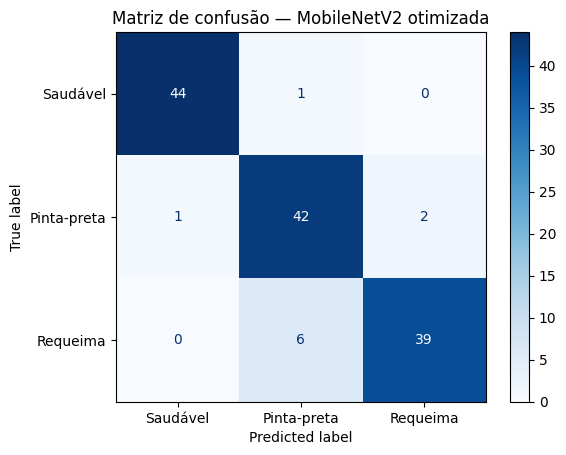

Folhas doentes classificadas como saudáveis: 1


In [ ]:
# CLASSIFICATION REPORT + MATRIZ DE CONFUSÃO DO MODELO ESCOLHIDO

# O conjunto de teste não foi usado durante o treino ou para escolher o vencedor.
probabilidades = melhor_modelo.predict(X_teste, verbose=0)
y_previsto = np.argmax(probabilidades, axis=1)

print('RELATÓRIO DE CLASSIFICAÇÃO —', vencedor)
print(classification_report(
    y_teste, y_previsto,
    labels=[0, 1, 2],
    target_names=NOMES_CLASSES,
    digits=3,
    zero_division=0
))

matriz = confusion_matrix(y_teste, y_previsto, labels=[0, 1, 2])
ConfusionMatrixDisplay(matriz, display_labels=NOMES_CLASSES).plot(
    cmap='Blues', values_format='d'
)
plt.title('Matriz de confusão — ' + vencedor)
plt.show()

# Conta o erro mais preocupante: folha doente classificada como saudável.
falsos_saudaveis = int(matriz[1, 0] + matriz[2, 0])
print('Folhas doentes classificadas como saudáveis:', falsos_saudaveis)

### 10.1 Interpretação da matriz de confusão e das métricas por classe

Na execução deste notebook, a **MobileNetV2 otimizada classificou corretamente 125 das 135 imagens de teste** e errou **10**, atingindo **92,59% de acurácia**. A matriz de confusão mostra os seguintes acertos por classe:

- **Saudável:** **44 de 45** imagens reconhecidas corretamente (**recall de 97,8%**).
- **Pinta-preta:** **42 de 45** reconhecidas corretamente (**recall de 93,3%**).
- **Requeima:** **39 de 45** reconhecidas corretamente (**recall de 86,7%**).

Os erros observados foram:

- **6 folhas com requeima** classificadas como **pinta-preta**.
- **2 folhas com pinta-preta** classificadas como **requeima**.
- **1 folha com pinta-preta** classificada como **saudável**.
- **1 folha saudável** classificada como **pinta-preta**.

O **F1-score macro foi 0,926**, indicando o equilíbrio médio entre *precision* e *recall* das três classes. A classe **requeima** continua com o menor *recall* (**86,7%**), e a maior confusão é entre as duas doenças, que têm manchas parecidas.

**Risco prático:** houve **1 caso de folha doente prevista como saudável**. Esse é o erro mais grave, porque impediria um alerta ao produtor. Já a troca entre pinta-preta e requeima ainda gera o aviso de possível doença e o pedido de avaliação técnica. Por isso o Heimdall deve ser apresentado como uma **triagem experimental**, nunca como diagnóstico agronômico definitivo, e precisa ser testado com fotos reais de campo antes de sair da demonstração acadêmica.

## 11. Demonstração funcional — imagem nunca usada no treino

Vamos enviar imagens **do conjunto de teste** à função `classificar_folha()`. Ela deverá retornar:

1. **Classe prevista** pela rede.
2. **Confiança** atribuída pela saída `softmax`.
3. **Mensagem simples** para o produtor.

A função usará **o mesmo modelo e o mesmo pré-processamento do treino**. A regra `confiança < 75%` significa que a classificação deve ser encaminhada para revisão humana. **75% é um limiar experimental de triagem, não uma validação agronômica.** Mesmo acima disso, um técnico precisa confirmar qualquer suspeita de doença.

In [ ]:
# FUNÇÃO PARA CLASSIFICAR UMA FOLHA

def classificar_folha(imagem):
    """Recebe um array de foto RGB ou um caminho de imagem e retorna a triagem."""

    # Se receber um caminho, abre a foto; senão, usa o array recebido.
    if isinstance(imagem, str):
        foto = Image.open(imagem).convert('RGB')
        foto = foto.resize((TAMANHO, TAMANHO))
        foto = np.array(foto, dtype=np.uint8)
    else:
        foto = np.asarray(imagem, dtype=np.uint8)
        if foto.shape != (TAMANHO, TAMANHO, 3):
            foto = Image.fromarray(foto).convert('RGB').resize((TAMANHO, TAMANHO))
            foto = np.array(foto, dtype=np.uint8)

    # A rede espera um LOTE. O np.expand_dims cria a dimensão do lote.
    entrada = np.expand_dims(foto, axis=0)  # (128,128,3) -> (1,128,128,3)

    # Normalização é aplicada dentro do modelo, por isso NÃO dividimos aqui.
    pontuacoes = melhor_modelo.predict(entrada, verbose=0)[0]
    indice = int(np.argmax(pontuacoes))
    confianca = float(pontuacoes[indice])
    classe_prevista = NOMES_CLASSES[indice]

    # Regra didática de encaminhamento ao produtor.
    if confianca < 0.75:
        mensagem = 'Confiança baixa: solicitar avaliação de um técnico agrícola.'
    elif indice == 0:
        mensagem = 'Triagem: sem sinais das duas doenças estudadas. Continuar monitorando.'
    else:
        mensagem = 'Possível doença detectada. Solicitar avaliação de um técnico agrícola.'

    return {
        'classe': classe_prevista,
        'confianca': confianca,
        'mensagem': mensagem
    }

Imagem real: Saudável
Previsão: Saudável
Confiança: 100.0%
Orientação: Triagem: sem sinais das duas doenças estudadas. Continuar monitorando. 

Imagem real: Pinta-preta
Previsão: Pinta-preta
Confiança: 98.0%
Orientação: Possível doença detectada. Solicitar avaliação de um técnico agrícola. 

Imagem real: Requeima
Previsão: Pinta-preta
Confiança: 91.2%
Orientação: Possível doença detectada. Solicitar avaliação de um técnico agrícola. 



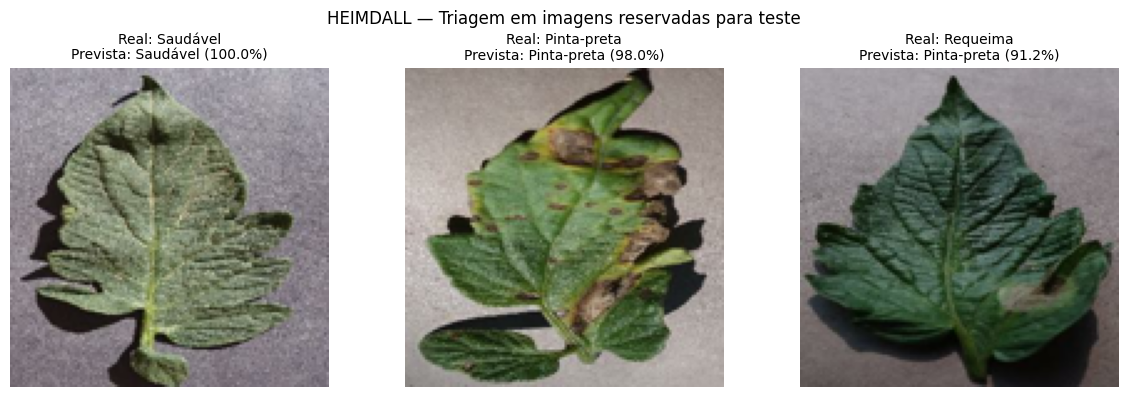

In [ ]:
# DEMONSTRAÇÃO: 1 FOTO DE TESTE DE CADA CLASSE

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for classe in range(3):
    # Seleciona a primeira foto de teste daquela classe.
    posicao = np.where(y_teste == classe)[0][0]
    foto = X_teste[posicao]
    resposta = classificar_folha(foto)

    axes[classe].imshow(foto)
    axes[classe].axis('off')
    axes[classe].set_title(
        f'Real: {NOMES_CLASSES[classe]}\n'
        f'Prevista: {resposta["classe"]} ({resposta["confianca"]:.1%})',
        fontsize=10
    )

    print('Imagem real:', NOMES_CLASSES[classe])
    print('Previsão:', resposta['classe'])
    print(f'Confiança: {resposta["confianca"]:.1%}')
    print('Orientação:', resposta['mensagem'], '\n')

plt.suptitle('HEIMDALL — Triagem em imagens reservadas para teste')
plt.tight_layout()
plt.show()

Saving teste_folha.jpg to teste_folha.jpg


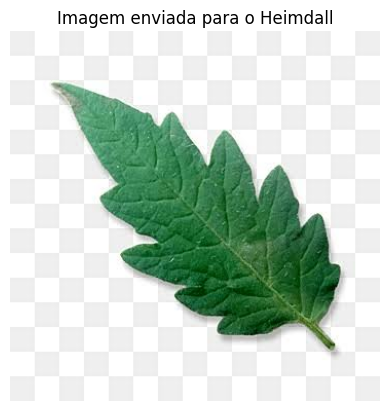

Classe prevista: Pinta-preta
Confiança: 99.80%
Orientação: Possível doença detectada. Solicitar avaliação de um técnico agrícola.


In [ ]:

# HEIMDALL - TESTAR UMA IMAGEM ENVIADA PELO USUÁRIO

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# 1. Abre a janela para escolher uma imagem do computador
arquivos = files.upload()

# 2. Pegar o nome da imagem enviada
nome_imagem = list(arquivos.keys())[0]

# 3. Abrir e mostrar a imagem
imagem = Image.open(nome_imagem).convert("RGB")

plt.imshow(imagem)
plt.title("Imagem enviada para o Heimdall")
plt.axis("off")
plt.show()

# 4. Enviar a imagem para a rede neural
resultado = classificar_folha(nome_imagem)

# 5. Mostrar o resultado
print("Classe prevista:", resultado["classe"])
print(f'Confiança: {resultado["confianca"]:.2%}')
print("Orientação:", resultado["mensagem"])


### 11.1 Interpretação da demonstração funcional

A função `classificar_folha()` foi testada com **três imagens reservadas para teste**, ou seja, não usadas para treinar os pesos da rede:

1. **Folha saudável:** predição **Saudável**, com **100,0%** de confiança. Correta.
2. **Folha com pinta-preta:** predição **Pinta-preta**, com **98,0%** de confiança. Correta.
3. **Folha com requeima:** predição **Pinta-preta**, com **91,2%** de confiança. **Incorreta**: o modelo errou a doença com confiança alta. Mesmo assim, como a previsão foi de doença, o sistema pediu a avaliação de um técnico.

Na demonstração adicional de **upload de imagem própria**, o arquivo `teste_folha.jpg` recebeu a classificação **Pinta-preta**, com **99,80% de confiança**, e o sistema orientou procurar avaliação técnica. Como a classe verdadeira dessa foto não está registrada no notebook, esse resultado demonstra o funcionamento da entrada e saída, **não comprova se a classificação foi correta**.

Esses exemplos confirmam que o notebook recebe imagens e devolve **classe prevista, pontuação de confiança e orientação**. O terceiro exemplo mostra o limite do limiar de **75%**: uma confiança alta não garante acerto. Ele é apenas uma regra experimental, não uma probabilidade agronômica calibrada.

## 12. Como a rede neural se integra ao Heimdall?

### Arquitetura simplificada do projeto integrador

```text
ELO 1 - Campo, irrigação:     ESP32 (AICSS) -> API Python -> previsão de umidade 24 h (ML)
ELO 2 - Campo, saúde:         foto da folha -> rede neural (esta disciplina) -> alerta ao produtor
ELO 3 - Armazenamento:        temperatura e risco de perda do lote (ESP32 + API)
ELO 4 - Varejo:               lotes em risco para venda rápida ou doação (API)
Dados de todos os elos:       Databricks e AWS -> visão por fazenda para cooperativas e redes
Segurança de todos os elos:   API blindada (Cybersecurity)
```

**O que já demonstramos neste notebook:** classificação de imagens de folhas de tomate com saída de classe, confiança e orientação.

**Como ela entra no Heimdall:** o produtor fotografa a folha suspeita pelo celular; a imagem é enviada à rede neural; o resultado (classe, confiança e orientação) é registrado na mesma API que recebe as leituras do ESP32. Assim, o painel da fazenda mostra no mesmo lugar o alerta de solo seco e o alerta de possível doença. Para uma cooperativa ou rede de varejo, isso significa saber antes quais fornecedores podem ter quebra de produção.

**O que ainda precisa ser desenvolvido:** o envio da foto pelo celular, o endpoint na API para receber a imagem e o registro do resultado no histórico da fazenda. A decisão de manejo continua sendo do produtor e do técnico.

### Limitações importantes
- A base é um conjunto de fotos geralmente padronizadas, diferente das condições de campo.
- Usamos **apenas 300 imagens por classe** e **somente três classes** de tomate.
- Imagens muito parecidas do mesmo ambiente ou planta podem levar a resultados otimistas; faltam identificadores de plantas para uma separação por origem.
- A saída `softmax` **não é uma probabilidade agronômica calibrada** nem comprova a presença de uma doença.
- Fotos de pessoas, coordenadas GPS e outros metadados devem ser evitados ou protegidos em uma futura aplicação, conforme a LGPD.

**ODS:** 2 (Fome Zero e Agricultura Sustentável), 9 (Indústria, Inovação e Infraestrutura) e 12 (Consumo e Produção Responsáveis).

## 13. Conclusão final do projeto

O projeto **Heimdall** teve como objetivo desenvolver uma rede neural capaz de analisar fotos de folhas de tomate e realizar uma **triagem inicial** entre três classes: **saudável, pinta-preta e requeima**. Utilizamos **900 imagens da base PlantVillage**, com **300 imagens por classe**, separadas em **70% para treino (630)**, **15% para validação (135)** e **15% para teste (135)**.

Foram treinadas e comparadas quatro configurações: **CNN simples**, **CNN melhorada com regularização**, **MobileNetV2 com transfer learning** e **MobileNetV2 otimizada** por uma busca de hiperparâmetros (learning rate, neurônios e batch size). A CNN simples teve treino alto e validação bem menor, com sinais de *overfitting*. A CNN melhorada não aprendeu nesta execução (*underfitting*). A **MobileNetV2 otimizada foi escolhida antes da avaliação final** por obter a **maior acurácia de validação (93,33%)**, com learning rate 0,001, 128 neurônios e batch 32.

No conjunto de teste, a MobileNetV2 otimizada obteve **92,59% de acurácia**, com **125 acertos entre 135 imagens**, e **F1-score macro de 0,926**, cerca de 8 pontos acima das outras configurações. O teste confirmou a escolha feita pela validação.

A matriz de confusão mostrou limitações relevantes: **1 folha doente foi classificada como saudável** e **6 imagens de requeima foram confundidas com pinta-preta**. Na demonstração, uma folha com requeima foi prevista como pinta-preta com 91,2% de confiança. Portanto, a rede neural **não deve substituir um profissional agrícola**, e as probabilidades da camada *softmax* não representam um diagnóstico calibrado.

A demonstração funcional mostrou que o Heimdall recebe imagens, retorna uma **classe prevista**, a **confiança** do modelo e uma **orientação ao produtor**. Na foto enviada manualmente, o modelo retornou **Pinta-preta (99,80%)** e pediu avaliação técnica, mas a classe verdadeira da foto não foi verificada nessa execução.

**Concluímos que o protótipo atende ao objetivo acadêmico de construir, comparar, otimizar, avaliar e demonstrar redes neurais**, com potencial para auxiliar pequenos produtores e cooperativas na triagem de folhas suspeitas. Antes do uso real, ainda seriam necessários dados adicionais, validação com fotos de campo e avaliação por profissionais. O envio da foto pelo celular e o registro do resultado na API do Heimdall permanecem como evolução futura.

### Melhorias possíveis para uma próxima versão

- Testar mais imagens e diferentes condições de iluminação, fundos e fotografias reais de lavouras.
- Estudar *fine-tuning* das últimas camadas da MobileNetV2 e mais épocas para a CNN melhorada.
- Priorizar a separação entre **pinta-preta e requeima** e a redução de **folhas doentes classificadas como saudáveis**.
- Integrar o envio de fotos ao Heimdall, mantendo supervisão humana para decisões de manejo.